# Question 8: Feature Selection and Visualization on the Heart Disease Dataset

# Feature Selection and Dimensionality Reduction
## Heart Disease Classification Study

### Objective
The purpose of this notebook is to compare multiple feature selection and dimensionality reduction techniques on a real-world medical dataset.

We evaluate each method based on:

- Predictive performance (accuracy)
- Model interpretability
- Stability
- Computational cost
- Dimensionality reduction effectiveness

The target variable is binary:
- 0 → No heart disease
- 1 → Presence of heart disease

Logistic Regression is used as the base classifier for fair comparison.


## 1. Imports and Data Loading

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Load dataset (make sure heart.csv is in same folder)
data = pd.read_csv('heart.csv')

X = data.drop('target', axis=1)
y = data['target']

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 2. Exploratory Data Analysis

We visualize feature distributions and compute the correlation matrix.

<Figure size 1500x1000 with 0 Axes>

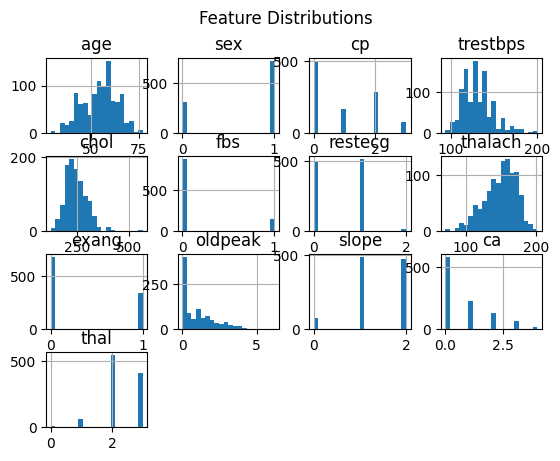

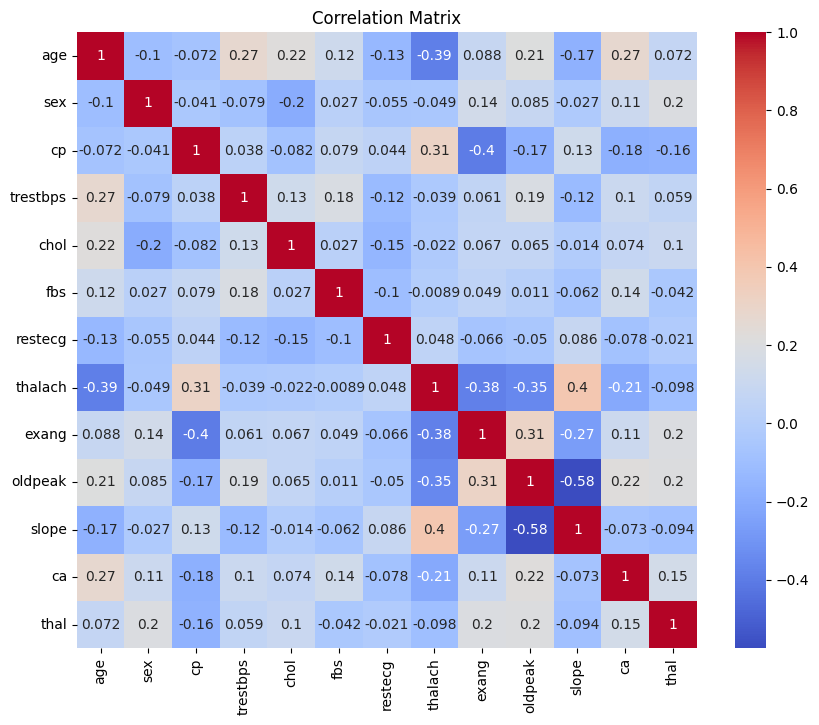

In [21]:
# Feature distributions
plt.figure(figsize=(15,10))
X.hist(bins=20)
plt.suptitle("Feature Distributions")
plt.show()

# Correlation matrix
plt.figure(figsize=(10,8))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

### Correlation-Based Filtering
We remove one feature from highly correlated pairs (threshold = 0.7).

### Motivation
Highly correlated features introduce:

- Multicollinearity
- Unstable coefficient estimates
- Increased variance
- Reduced interpretability

### Method
1. Compute the correlation matrix.
2. Identify feature pairs with |correlation| > 0.7.
3. Remove one feature from each highly correlated pair.

### Characteristics
- Filter method
- Unsupervised
- Very fast
- Improves model stability


In [13]:
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [column for column in upper_triangle.columns if any(abs(upper_triangle[column]) > 0.7)]

print("Highly correlated features removed:", to_drop)

X_filtered = X.drop(columns=to_drop)

Highly correlated features removed: []


## 3. Train/Test Split and Standardization

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Univariate Feature Selection (Mutual Information)

In [15]:
k = 5
mi_selector = SelectKBest(mutual_info_classif, k=k)
X_train_mi = mi_selector.fit_transform(X_train_scaled, y_train)
X_test_mi = mi_selector.transform(X_test_scaled)

selected_mi = X_train.columns[mi_selector.get_support()]
print("Selected features (Mutual Info):", list(selected_mi))

model = LogisticRegression(max_iter=500)
model.fit(X_train_mi, y_train)
acc_mi = accuracy_score(y_test, model.predict(X_test_mi))

model.fit(X_train_scaled, y_train)
acc_full = accuracy_score(y_test, model.predict(X_test_scaled))

print("Accuracy (Full Features):", acc_full)
print("Accuracy (Mutual Info):", acc_mi)

Selected features (Mutual Info): ['cp', 'chol', 'thalach', 'ca', 'thal']
Accuracy (Full Features): 0.8097560975609757
Accuracy (Mutual Info): 0.8048780487804879


## 5. Recursive Feature Elimination (RFE)

### Concept

RFE is a wrapper method that:

1. Trains a model
2. Computes feature importance
3. Removes the least important feature
4. Repeats until desired number of features remains

Unlike filter methods, RFE considers feature interactions.

### Advantages
- Higher predictive performance
- Interaction-aware

### Disadvantages
- Computationally expensive
- Requires model training multiple times


In [16]:
rfe = RFE(LogisticRegression(max_iter=500), n_features_to_select=k)
X_train_rfe = rfe.fit_transform(X_train_scaled, y_train)
X_test_rfe = rfe.transform(X_test_scaled)

selected_rfe = X_train.columns[rfe.get_support()]
print("Selected features (RFE):", list(selected_rfe))

model.fit(X_train_rfe, y_train)
acc_rfe = accuracy_score(y_test, model.predict(X_test_rfe))
print("Accuracy (RFE):", acc_rfe)

Selected features (RFE): ['sex', 'cp', 'exang', 'oldpeak', 'ca']
Accuracy (RFE): 0.8536585365853658


## 6. RFECV (RFE with Cross-Validation)

RFECV extends RFE by automatically selecting the optimal number of features.

Procedure:
1. Perform RFE
2. Evaluate model performance using cross-validation
3. Select feature count that maximizes validation accuracy

### Benefit
More stable and less arbitrary than choosing fixed k.

### Trade-off
Higher computational cost.


In [17]:
rfecv = RFECV(LogisticRegression(max_iter=500), cv=5)
rfecv.fit(X_train_scaled, y_train)

selected_rfecv = X_train.columns[rfecv.get_support()]
print("Selected features (RFECV):", list(selected_rfecv))

model.fit(X_train_scaled[:, rfecv.get_support()], y_train)
acc_rfecv = accuracy_score(
    y_test,
    model.predict(X_test_scaled[:, rfecv.get_support()])
)
print("Accuracy (RFECV):", acc_rfecv)

Selected features (RFECV): ['age', 'sex', 'cp', 'trestbps', 'chol', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Accuracy (RFECV): 0.8097560975609757


## 7. L1-Regularized Logistic Regression (Embedded Method)

L1 regularization adds a penalty to the loss function:

Loss = Logistic Loss + λ Σ |βᵢ|

This forces some coefficients to become exactly zero.

Features with zero coefficients are automatically removed.

### Advantages
- Embedded method
- Efficient
- Produces sparse models
- Maintains interpretability


In [18]:
lasso = LogisticRegression(penalty='l1', solver='liblinear', max_iter=500)
lasso.fit(X_train_scaled, y_train)

coef = pd.Series(lasso.coef_[0], index=X_train.columns)
selected_lasso = coef[coef != 0].index
print("Selected features (L1):", list(selected_lasso))

Selected features (L1): ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


## 8. Principal Component Analysis (PCA)

PCA transforms the original features into orthogonal components that maximize variance.

Steps:
1. Standardize features
2. Compute covariance matrix
3. Calculate eigenvectors and eigenvalues
4. Sort by explained variance

We select the number of components that explain 95% of total variance.

### Important Note
PCA is unsupervised — it does not use the target variable.

### Trade-off
Reduces dimensionality but sacrifices interpretability.


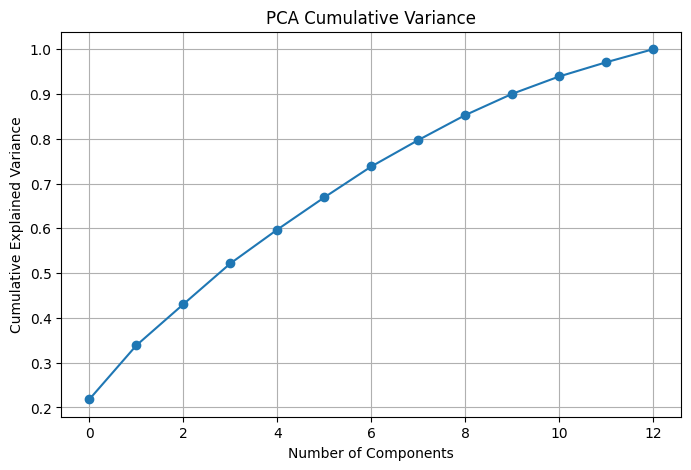

Components needed for 95% variance: 12


In [19]:
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(cumulative_variance, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Variance")
plt.grid()
plt.show()

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed for 95% variance:", n_components_95)

## Results Interpretation

When comparing methods, consider:

- Does accuracy improve or remain stable?
- How many features are selected?
- Is the method stable across splits?
- Is interpretability preserved?

Typically:
- Wrapper methods yield higher accuracy.
- L1 regularization balances sparsity and performance.
- PCA reduces dimension but may slightly reduce classification accuracy.


In [22]:
# Evaluate L1-regularized Logistic Regression using selected features
model_l1 = LogisticRegression(max_iter=500)
X_train_l1 = X_train_scaled[:, [X_train.columns.get_loc(c) for c in selected_lasso]]
X_test_l1 = X_test_scaled[:, [X_train.columns.get_loc(c) for c in selected_lasso]]

model_l1.fit(X_train_l1, y_train)
acc_l1 = accuracy_score(y_test, model_l1.predict(X_test_l1))

# Evaluate PCA-based logistic regression using components that explain 95% variance
pca_95 = PCA(n_components=n_components_95)
X_train_pca_95 = pca_95.fit_transform(X_train_scaled)
X_test_pca_95 = pca_95.transform(X_test_scaled)

model_pca = LogisticRegression(max_iter=500)
model_pca.fit(X_train_pca_95, y_train)
acc_pca = accuracy_score(y_test, model_pca.predict(X_test_pca_95))

# Final comparison table
print("\nFinal Accuracy Comparison")
print("Full:", acc_full)
print("Mutual Info:", acc_mi)
print("RFE:", acc_rfe)
print("RFECV:", acc_rfecv)
print("L1:", acc_l1)
print("PCA:", acc_pca)

print("\nNumber of Features Selected / Components")
print("Mutual Info:", len(selected_mi))
print("RFE:", len(selected_rfe))
print("RFECV:", len(selected_rfecv))
print("L1:", len(selected_lasso))
print("PCA Components (95% variance):", n_components_95)



Final Accuracy Comparison
Full: 0.8097560975609757
Mutual Info: 0.8048780487804879
RFE: 0.8536585365853658
RFECV: 0.8097560975609757
L1: 0.8097560975609757
PCA: 0.8097560975609757

Number of Features Selected / Components
Mutual Info: 5
RFE: 5
RFECV: 12
L1: 13
PCA Components (95% variance): 12


## Final Conclusion

This study demonstrates that:

- Filter methods are fast but ignore interactions.
- Wrapper methods are accurate but computationally expensive.
- Embedded methods offer strong balance between sparsity and performance.
- PCA is effective for dimensionality reduction but reduces interpretability.

For medical datasets where explanation is important, L1 regularization and RFECV are strong choices.
